# Codebook 

**Plotting the prepared yearly and monthly data from Norkyst 2024 (Hindcast)**

- For information about the used datasets, refer to histogram_norkyst_yearly_seasonal.ipynb, where the yearly and monthly datasets were calculated. 

In [3]:
import numpy as np
import scipy as sp
import xarray as xr
import seaborn as sea
import matplotlib.pyplot as plt

In [4]:
path = '/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/saved_nc'
year = xr.open_dataset(f'{path}/yearly_average.nc')
month = xr.open_dataset(f'{path}/monthly_average.nc')
#viewing files to ensure correct calculations: 
print(year.head())
print(month.head())

<xarray.Dataset> Size: 1kB
Dimensions:      (X: 5, Y: 5, time: 1)
Coordinates:
    s_rho        float64 8B ...
  * X            (X) float64 40B 0.0 800.0 1.6e+03 2.4e+03 3.2e+03
  * Y            (Y) float64 40B 0.0 800.0 1.6e+03 2.4e+03 3.2e+03
    s_w          float64 8B ...
    lon          (Y, X) float64 200B ...
    lat          (Y, X) float64 200B ...
  * time         (time) datetime64[ns] 8B 2024-12-31
Data variables:
    salinity     (time, Y, X) float32 100B ...
    temperature  (time, Y, X) float32 100B ...
    v_northward  (time, Y, X) float32 100B ...
    u_eastward   (time, Y, X) float32 100B ...
    zeta         (time, Y, X) float32 100B ...
Attributes:
    grid:                   grid
    location:               face
    field:                  salinity, scalar, series
    grid_mapping:           projection_stere
    long_name:              Sea water salinity
    standard_name:          sea_water_salinity
    coverage_content_type:  modelResult
    units:                 

In [35]:
#check if code from summer project is adaptable for this use case
sea.set_theme(style="darkgrid")
def histograms_with_specified_layout(ds, type_of_avg, type_to_check = 'time', time_to_check = 1, save_path = 'figures/histogram.png'):
    """
    Definition: 

    Arguments:
    arg[1] : dataset - the inference dataset 
    arg[2] : time to check (int) - the timestep in the data would you like the check the variable distribution for

    Outputs: 
    Figure of the variable distributions 
    """

    variables = ['salinity', 'u_eastward', 'v_northward', 'temperature', 'zeta']
    data = {var: ds[var].isel({type_to_check : time_to_check}).values.ravel() for var in variables}
    #data = {var : ds[var].sel({type_to_check} = {time_to_check}).values.ravel() for var in variables}
    data = {var : values[~np.isnan(values)] for var, values in data.items()}

    fig = plt.figure(figsize = (12,7))
    titles = ['Salinity', 'U-Eastward', 'V-Northward', 'temperature', 'zeta']
    """ 
    Trying to make the plot more visually appealing witg gridspec, to elongate the bottom plots.
    """
    gs = fig.add_gridspec(2,6)
    axes = [fig.add_subplot(gs[0,0:2]), fig.add_subplot(gs[0,2:4]), fig.add_subplot(gs[0,4:6]), fig.add_subplot(gs[1,0:3]), fig.add_subplot(gs[1,3:6])]
    
    for i, (var, values) in enumerate(data.items()):
        row, col = divmod(i,3)
        sea.histplot(values, bins = 30, kde = True, ax = axes[i], stat='density', color = 'royalblue', edgecolor = 'darkolivegreen')
        axes[i].set_title(titles[i], fontsize = 15)
        axes[i].set_facecolor("#C4C6D5")
        #axes[1,2].axis('off')

    plt.suptitle(f'Histogram & Density curve for Norkyst variables - {type_of_avg} average')
    plt.tight_layout()
    fig.savefig(save_path)

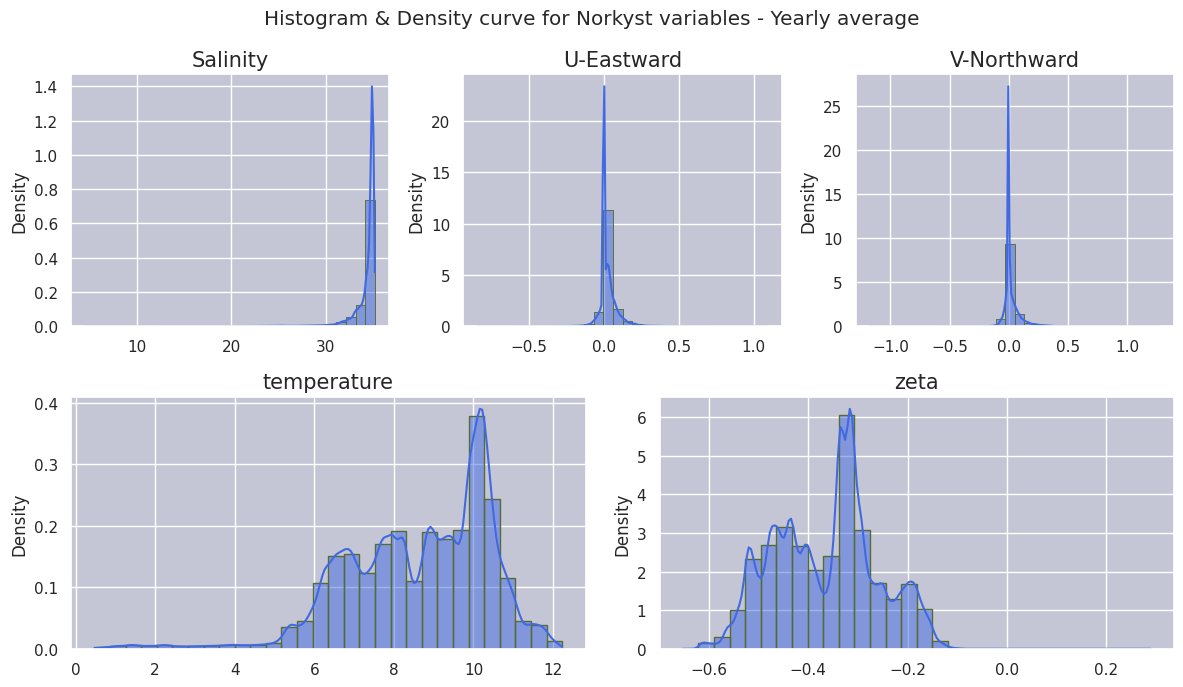

In [6]:
histograms_with_specified_layout(year, 'Yearly', time_to_check=0, save_path='/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/figures/year.png')

In [24]:
def seasons(ds):
    #Then we make weights based on the number of days in the respective months
    month_length = ds.time.dt.days_in_month
    #Preview
    print(month_length)
    #Weights - tid per måned / summen av alle tider  
    weights = month_length.groupby('time.season') / month_length.groupby('time.season').sum()
    #testing to make sure the weights are correctly defined
    #weight_summed = np.testing.assert_allclose(weights.groupby('time.season').sum().values, np.ones(4)) 
    #if weight_summed != 1:
    #    raise ValueError(f'Weights are not properly defined - please ensure that the sum of weights for the seasons equal 1.0. Current sum is: {weight_summed}')
    #apply weights to dataset
    ds_weighted = (ds*weights).groupby('time.season').sum(dim = 'time')
    return ds_weighted 

In [25]:
seasons_ds = seasons(month)

<xarray.DataArray 'days_in_month' (time: 12)> Size: 96B
array([31, 29, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])
Coordinates:
    s_rho    float64 8B ...
    s_w      float64 8B ...
  * time     (time) datetime64[ns] 96B 2024-01-01 2024-02-01 ... 2024-12-01
Attributes:
    long_name:      time since initialization
    field:          time, scalar, series
    axis:           T
    standard_name:  time


In [18]:
month_length = month.time.dt.days_in_month
#Preview
print(month_length)
#Weights - tid per måned / summen av alle tider  
weights = month_length.groupby('time.season') / month_length.groupby('time.season').sum()
#testing to make sure the weights are correctly defined
weight_summed = np.testing.assert_allclose(weights.groupby('time.season').sum().values, np.ones(4)) 
print(weight_summed)


<xarray.DataArray 'days_in_month' (time: 12)> Size: 96B
array([31, 29, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])
Coordinates:
    s_rho    float64 8B ...
    s_w      float64 8B ...
  * time     (time) datetime64[ns] 96B 2024-01-01 2024-02-01 ... 2024-12-01
Attributes:
    long_name:      time since initialization
    field:          time, scalar, series
    axis:           T
    standard_name:  time
None


In [20]:
month_length.groupby('time.season')

<DataArrayGroupBy, grouped over 1 grouper(s), 4 groups in total:
    'season': 4/4 groups present with labels 'DJF', 'JJA', 'MAM', 'SON'>

In [21]:
month_length.groupby('time.season').sum()

<xarray.DataArray 'days_in_month' (season: 4)> Size: 32B
array([91, 92, 92, 91])
Coordinates:
    s_rho    float64 8B ...
    s_w      float64 8B ...
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
Attributes:
    long_name:      time since initialization
    field:          time, scalar, series
    axis:           T
    standard_name:  time

In [22]:
month_length.groupby('time.season') / month_length.groupby('time.season').sum()

<xarray.DataArray 'days_in_month' (time: 12)> Size: 96B
array([0.34065934, 0.31868132, 0.33695652, 0.32608696, 0.33695652,
       0.32608696, 0.33695652, 0.33695652, 0.32967033, 0.34065934,
       0.32967033, 0.34065934])
Coordinates:
    s_rho    (time) float64 96B -0.004904 -0.004904 ... -0.004904 -0.004904
    s_w      (time) float64 96B 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0
  * time     (time) datetime64[ns] 96B 2024-01-01 2024-02-01 ... 2024-12-01
    season   (time) object 96B 'DJF' 'DJF' 'MAM' 'MAM' ... 'SON' 'SON' 'DJF'

In [23]:
weights.groupby('time.season').sum().values

array([1., 1., 1., 1.])

In [26]:
seasons_ds

<xarray.Dataset> Size: 555MB
Dimensions:      (season: 4, Y: 1148, X: 2747)
Coordinates:
  * X            (X) float64 22kB 0.0 800.0 1.6e+03 ... 2.196e+06 2.197e+06
  * Y            (Y) float64 9kB 0.0 800.0 1.6e+03 ... 9.168e+05 9.176e+05
    lon          (Y, X) float64 25MB 8.7 8.706 8.711 8.717 ... 18.29 18.31 18.33
    lat          (Y, X) float64 25MB 54.29 54.3 54.31 ... 75.71 75.72 75.73
  * season       (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
Data variables:
    salinity     (season, Y, X) float64 101MB 0.0 0.0 0.0 ... 34.42 34.42 34.42
    temperature  (season, Y, X) float64 101MB 0.0 0.0 0.0 ... 4.272 4.284 4.281
    v_northward  (season, Y, X) float64 101MB 0.0 0.0 ... -0.006615 -0.006615
    u_eastward   (season, Y, X) float64 101MB 0.0 0.0 0.0 ... -0.03774 -0.03774
    zeta         (season, Y, X) float64 101MB 0.0 0.0 0.0 ... -0.4627 -0.4627

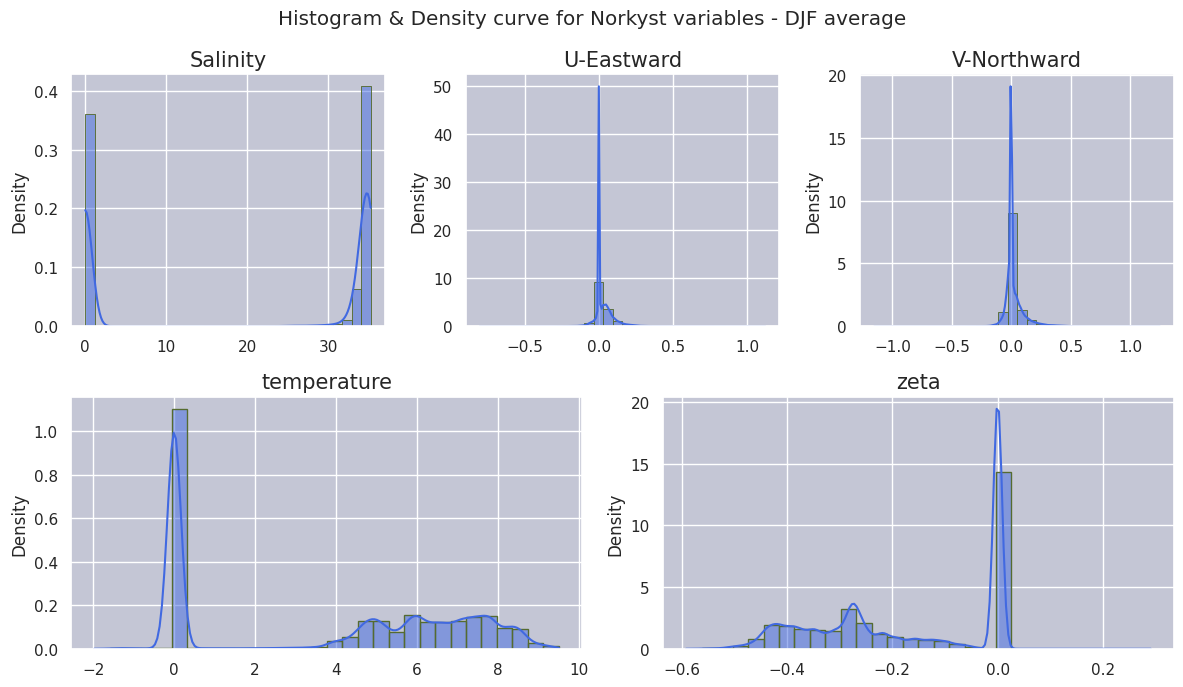

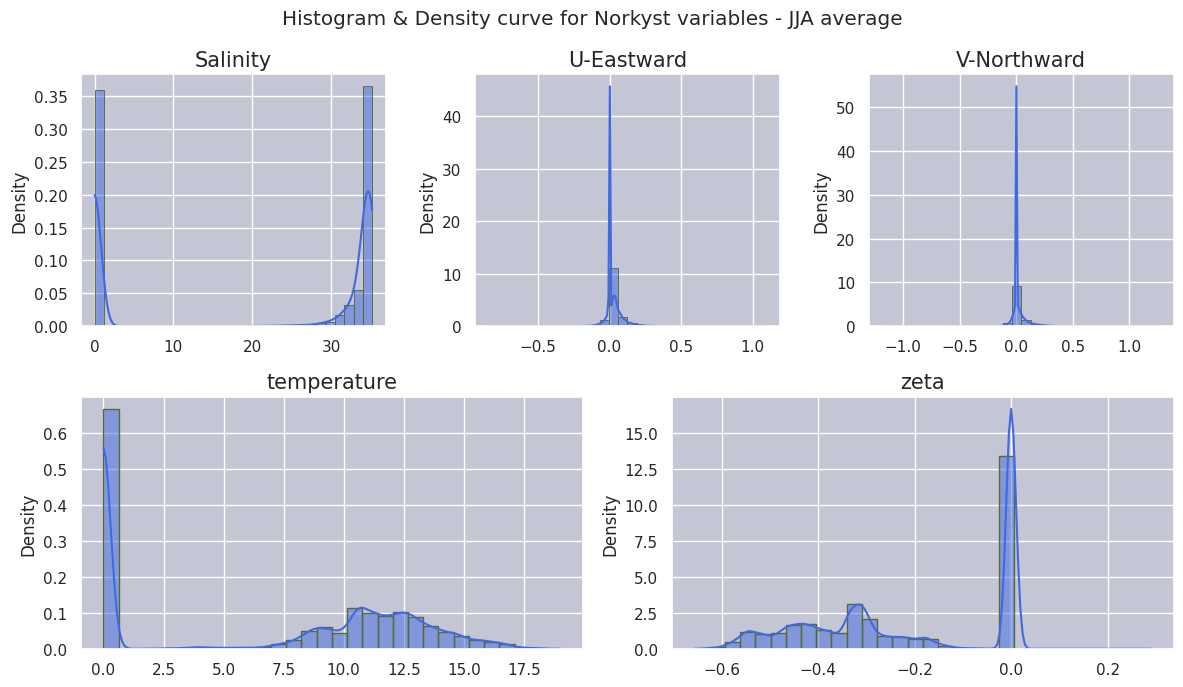

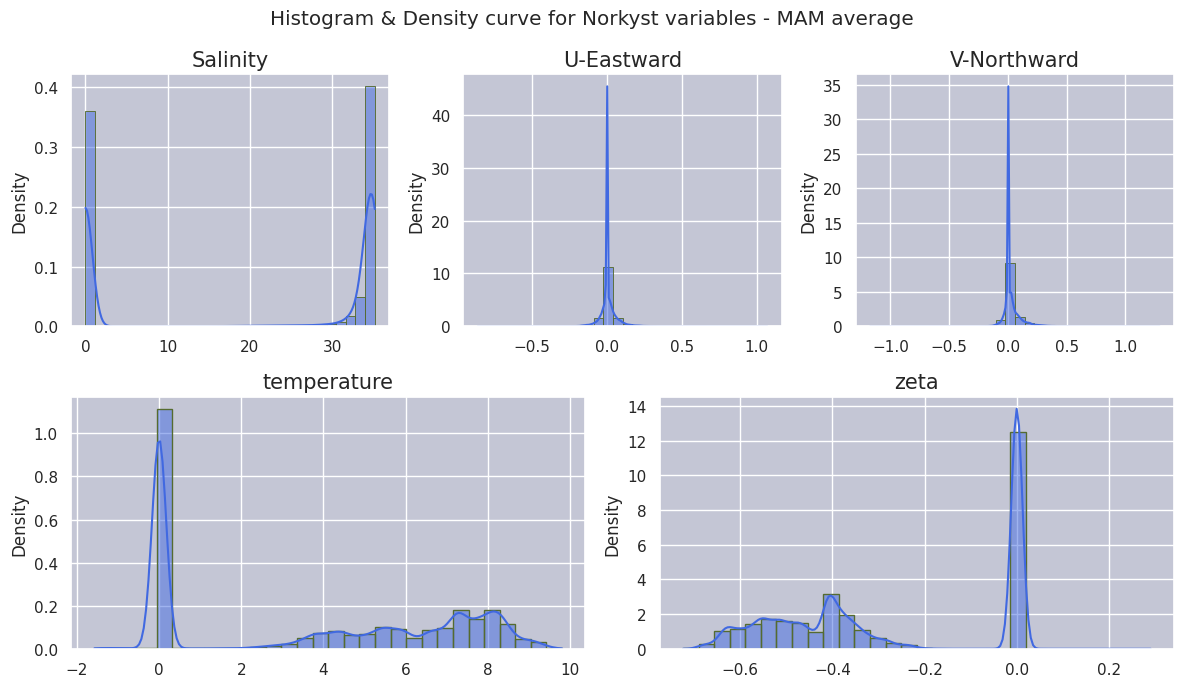

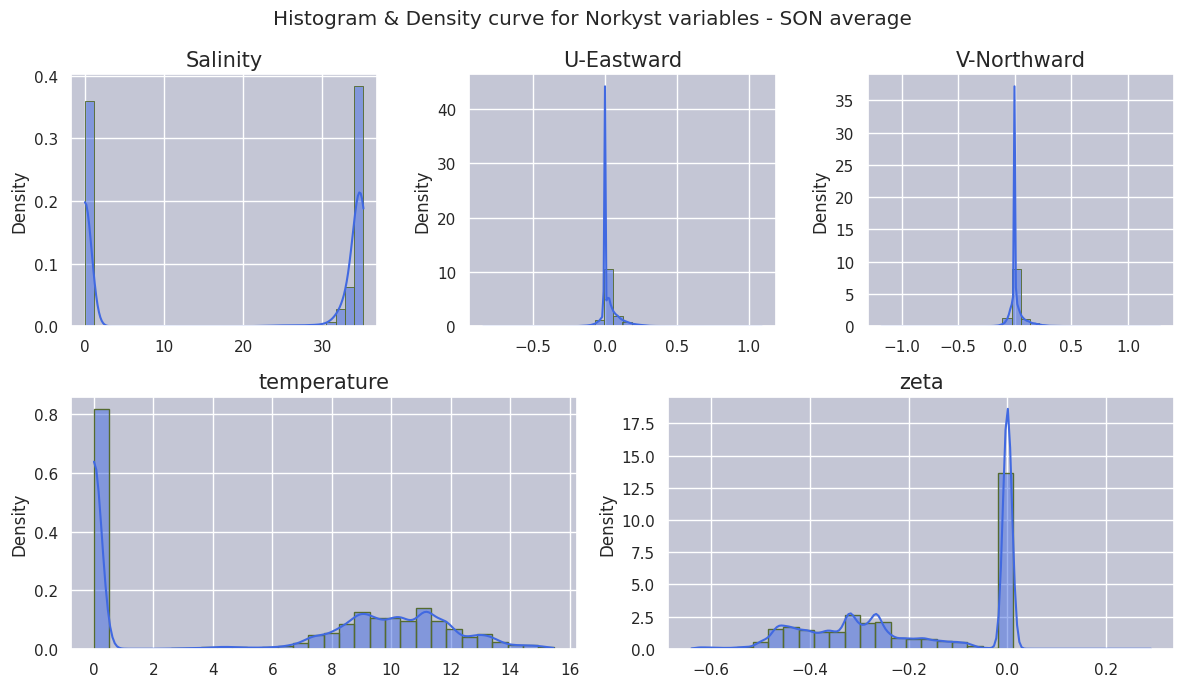

In [36]:
t = ['DJF', 'JJA', 'MAM', 'SON']
for i,n in enumerate(t):
    histograms_with_specified_layout(seasons_ds, f'{n}', type_to_check='season', time_to_check=i, save_path=f'/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/figures/season_{n}.png')

In [48]:
#sidebyside
#check if code from summer project is adaptable for this use case
sea.set_theme(style="darkgrid")
def histograms_sidebyside(ds, type_of_avg, variable, type_to_check = 'time', time_to_check = 1, save_path = 'figures/histogram.png'):
    """
    Definition: 

    Arguments:
    arg[1] : dataset - the inference dataset 
    arg[2] : time to check (int) - the timestep in the data would you like the check the variable distribution for

    Outputs: 
    Figure of the variable distributions 
    """

    variables = [f'{variable}']
    data = {time: ds[variable].isel({type_to_check : time}).values.ravel() for time in time_to_check}
    #data = {var : ds[var].sel({type_to_check} = {time_to_check}).values.ravel() for var in variables}
    data = {var : values[~np.isnan(values)] for var, values in data.items()}

    fig = plt.figure(figsize = (12,7))
    titles = ['DJF', 'JJA', 'MAM', 'SON']
    """ 
    Trying to make the plot more visually appealing witg gridspec, to elongate the bottom plots.
    """
    gs = fig.add_gridspec(2,4)
    axes = [fig.add_subplot(gs[0,0:2]), fig.add_subplot(gs[0,2:4]), fig.add_subplot(gs[1,0:2]), fig.add_subplot(gs[1,2:4])]
    
    for i, (var, values) in enumerate(data.items()):
        row, col = divmod(i,2)
        sea.histplot(values, bins = 30, kde = True, ax = axes[i], stat='density', color = 'royalblue', edgecolor = 'darkolivegreen')
        axes[i].set_title(titles[i], fontsize = 15)
        axes[i].set_facecolor("#C4C6D5")
        #axes[1,2].axis('off')

    plt.suptitle(f'Histogram & Density curve for Norkyst variables - {type_of_avg} average')
    plt.tight_layout()
    fig.savefig(save_path)

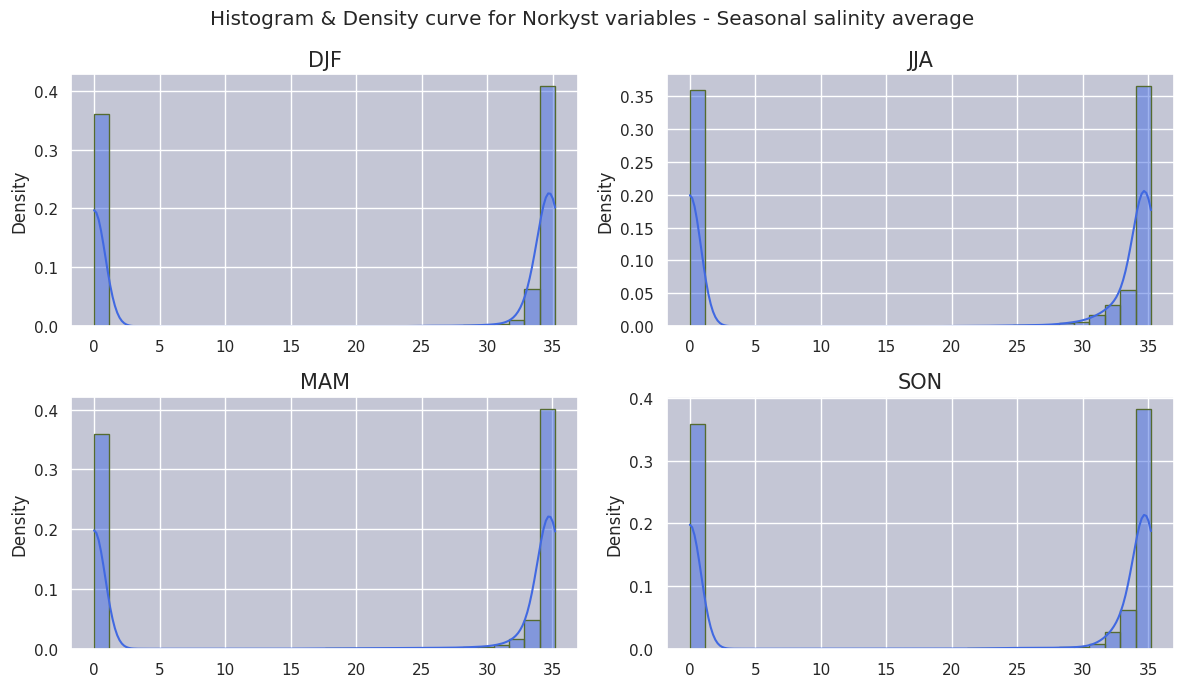

In [49]:
t = ['DJF', 'JJA', 'MAM', 'SON']
i = [0,1,2,3]
histograms_sidebyside(seasons_ds, f'Seasonal salinity', f'salinity', type_to_check='season', time_to_check=i, save_path=f'/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/figures/season_salinity.png')

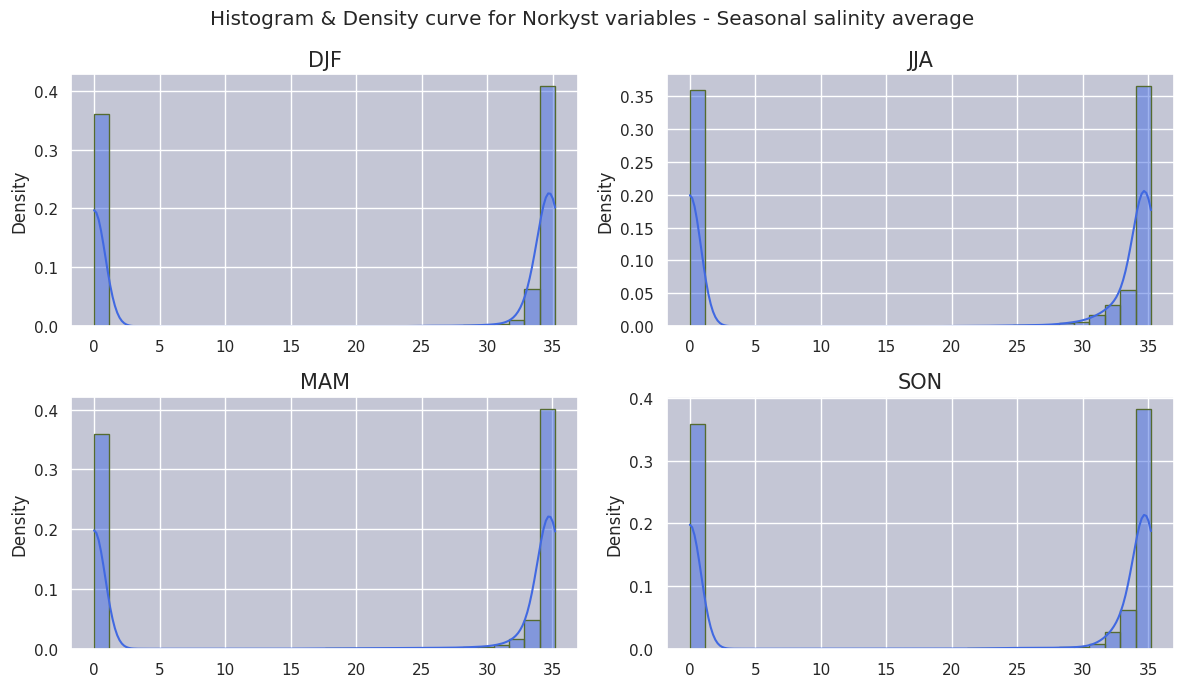

In [ ]:
t = ['DJF', 'JJA', 'MAM', 'SON']
i = [0,1,2,3]
histograms_sidebyside(seasons_ds, f'Seasonal salinity', f'salinity', type_to_check='season', time_to_check=i, save_path=f'/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/figures/season_salinity.png')

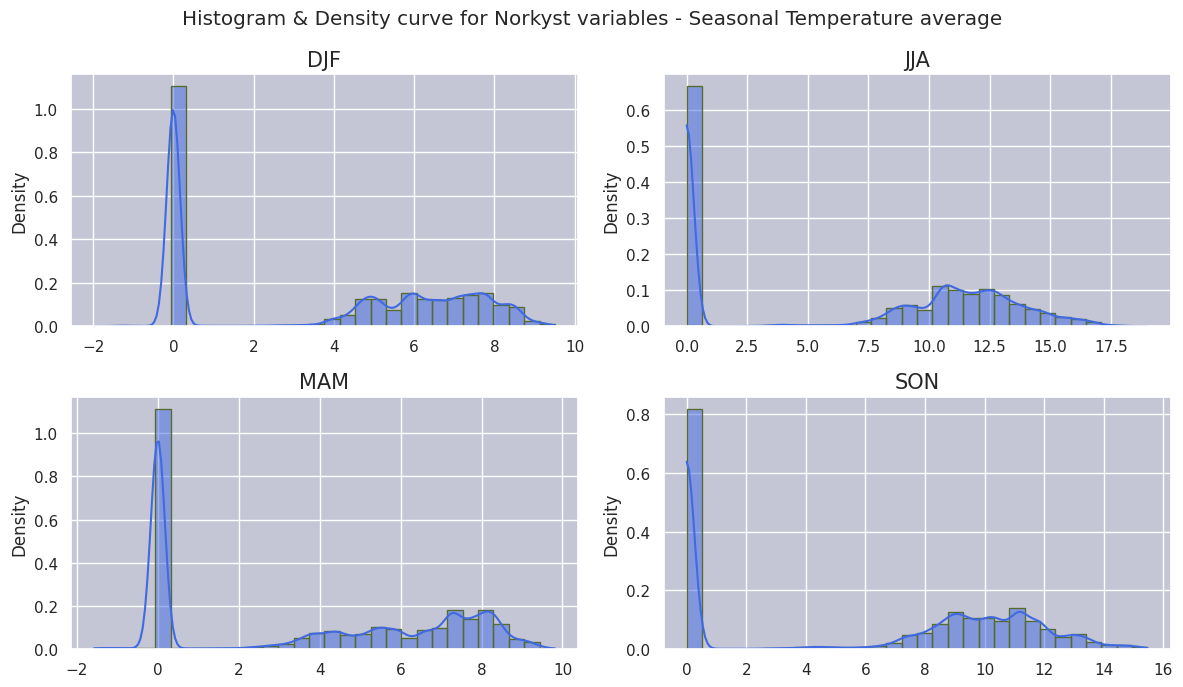

In [50]:
t = ['DJF', 'JJA', 'MAM', 'SON']
i = [0,1,2,3]
histograms_sidebyside(seasons_ds, f'Seasonal Temperature', f'temperature', type_to_check='season', time_to_check=i, save_path=f'/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/figures/season_temperature.png')

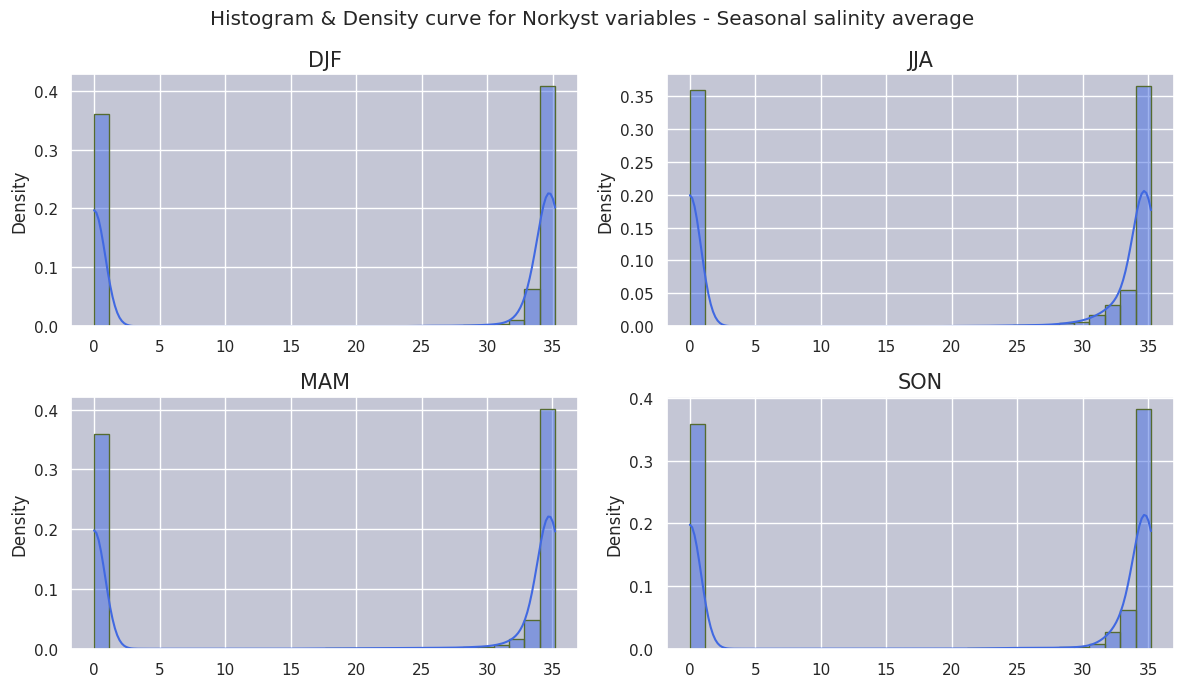

In [ ]:
t = ['DJF', 'JJA', 'MAM', 'SON']
i = [0,1,2,3]
histograms_sidebyside(seasons_ds, f'Seasonal salinity', f'salinity', type_to_check='season', time_to_check=i, save_path=f'/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/figures/season_salinity.png')

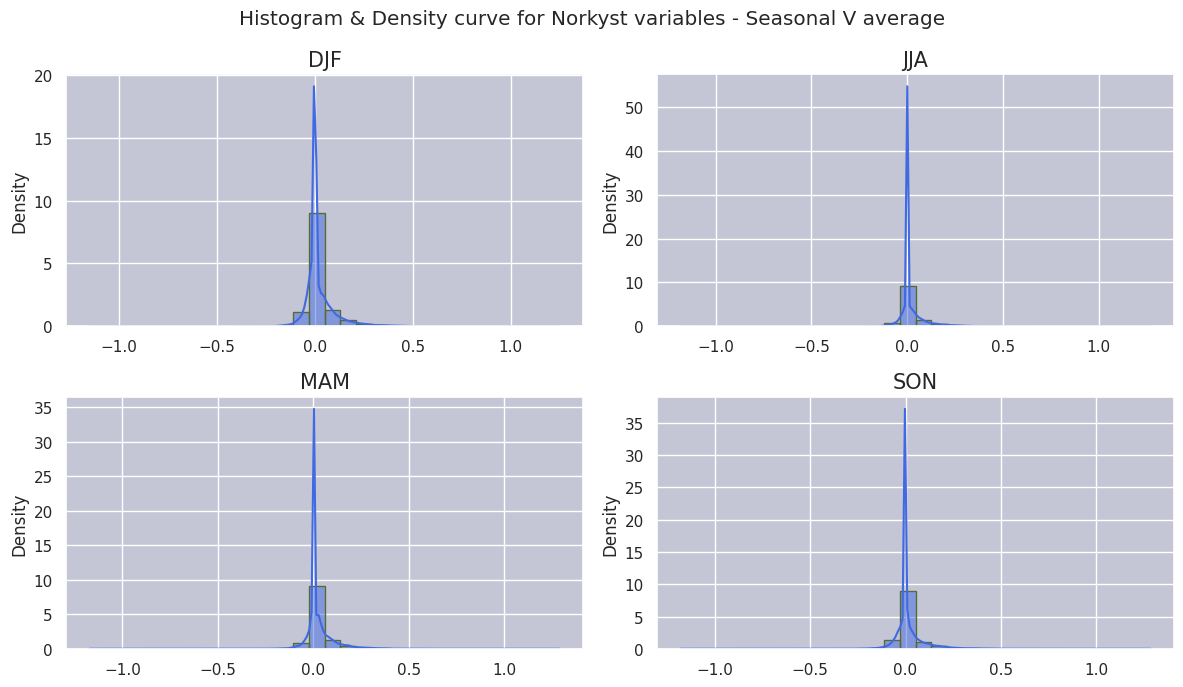

In [51]:
t = ['DJF', 'JJA', 'MAM', 'SON']
i = [0,1,2,3]
histograms_sidebyside(seasons_ds, f'Seasonal V', f'v_northward', type_to_check='season', time_to_check=i, save_path=f'/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/figures/season_vnorth.png')

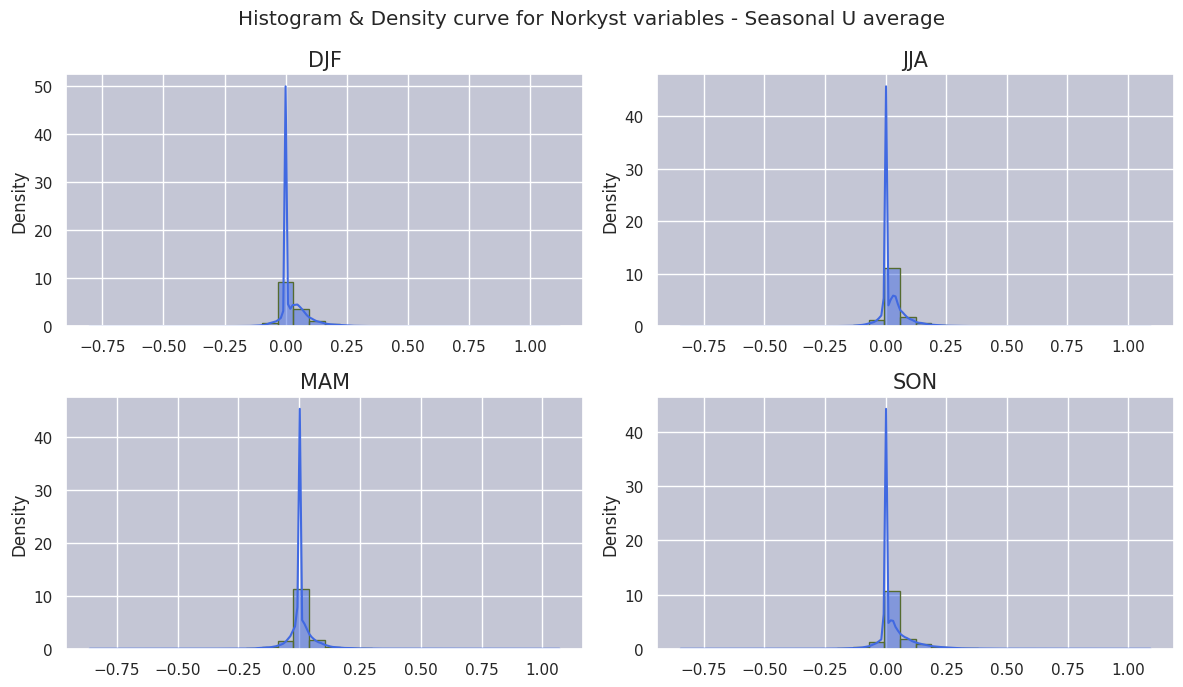

In [52]:
t = ['DJF', 'JJA', 'MAM', 'SON']
i = [0,1,2,3]
histograms_sidebyside(seasons_ds, f'Seasonal U', f'u_eastward', type_to_check='season', time_to_check=i, save_path=f'/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/figures/season_ueast.png')

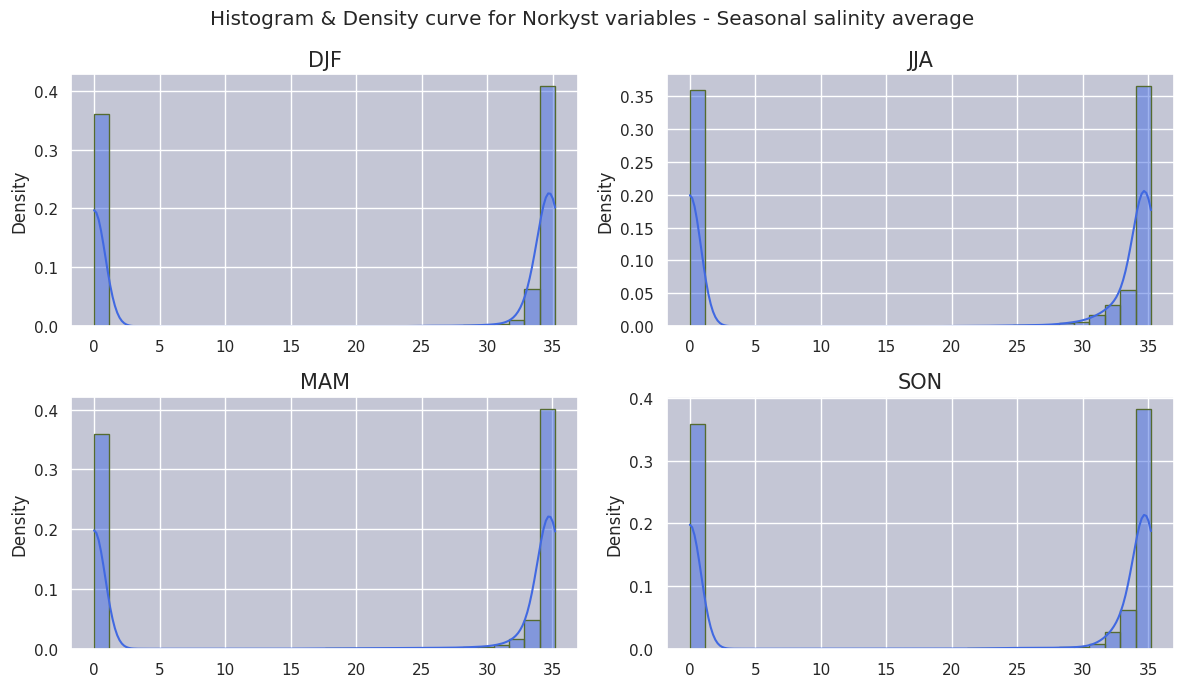

In [ ]:
t = ['DJF', 'JJA', 'MAM', 'SON']
i = [0,1,2,3]
histograms_sidebyside(seasons_ds, f'Seasonal salinity', f'salinity', type_to_check='season', time_to_check=i, save_path=f'/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/figures/season_salinity.png')

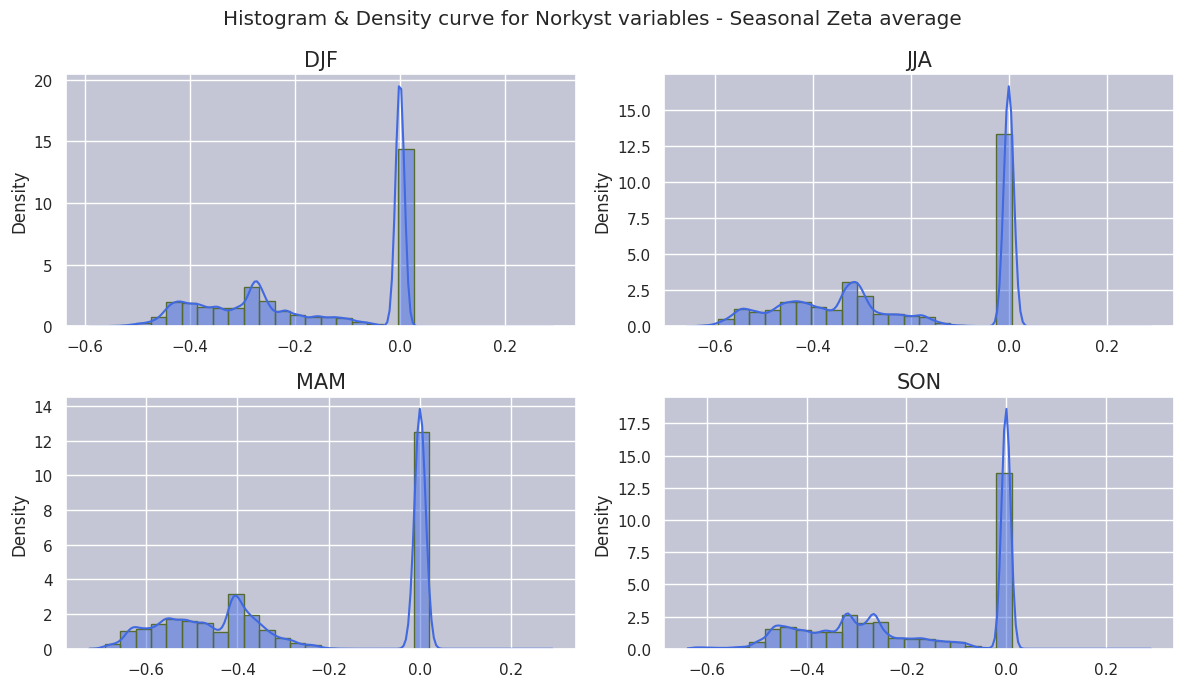

In [53]:
t = ['DJF', 'JJA', 'MAM', 'SON']
i = [0,1,2,3]
histograms_sidebyside(seasons_ds, f'Seasonal Zeta', f'zeta', type_to_check='season', time_to_check=i, save_path=f'/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/figures/season_zeta.png')